# PM2.5 trạm Việt Nam so với mạng trạm CNEMC (Trung Quốc)

So sánh **cấu trúc dữ liệu** và **phân phối PM2.5 theo giờ** giữa:

- **Việt Nam** — trạm tedp.vn / Envisoft sau QC: `/home/slow_data/Air_Quality/AQI/process/` (`filter_aqi.py`).
- **CNEMC** — mạng trạm quốc gia Trung Quốc (nguồn mặt đất của GTWNN, GTW-Tree, ASTMNN, STLG):
  `/home/slow_data/Air_Quality/AQI/china/` (`Data_Collection/AQI/china_crawl.py`, toạ độ từ `china_stations.py`).

Mục đích: biết hai bộ dữ liệu khác nhau ở đâu trước khi đem phương pháp của các paper Trung Quốc sang Việt Nam.

**So sánh công bằng.** Số liệu Việt Nam đã qua QC (bỏ giờ ngoài [3, 350] µg/m³, đoạn kẹt, trạm-tháng hỏng…);
CNEMC là số liệu công bố, chưa lọc. Vì vậy các phép so sánh phân phối dùng CNEMC **giới hạn trong [3, 350]**
(`cn_ok`); bảng 4.a có thêm cột CNEMC thô để thấy phần bị cắt.

**Vùng.** Việt Nam: Bắc (NW, NE, RRD, NCC) / Nam (SCC, CH, SE) theo `envisoft_station_map.csv`.
Trung Quốc: chia theo vĩ độ — Nam (< 26°N, gồm Quảng Tây, Vân Nam, Quảng Đông, Hải Nam, sát biên giới Việt Nam),
Trung (26–34°N), Bắc (≥ 34°N).

Mục lục: 0. Nạp dữ liệu · 1. Cấu trúc dữ liệu · 2. Mạng trạm · 3. Độ phủ thời gian · 4. Phân phối giá trị giờ ·
5. Phân phối theo trạm · 6. Biến thiên theo thời gian · 7. Tóm tắt

## 0. Nạp dữ liệu

In [1]:
%matplotlib inline
%run _aqi_common.py
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ensure_fig_dir()
VALID = (3.0, 350.0)   # khoảng giữ lại của filter_aqi.py
VN_ZONE = {'NW': 'VN-N', 'NE': 'VN-N', 'RRD': 'VN-N', 'NCC': 'VN-N',
           'SCC': 'VN-S', 'CH': 'VN-S', 'SE': 'VN-S'}
GROUPS = ['VN-N', 'VN-S', *CNEMC_ZONE_ORDER]
GROUP_NAMES = {'VN-N': 'Bắc VN', 'VN-S': 'Nam VN', **CNEMC_ZONE_NAMES}
GROUP_SHORT = {'VN-N': 'Bắc VN', 'VN-S': 'Nam VN', 'CN-S': 'Nam TQ', 'CN-C': 'Trung TQ', 'CN-N': 'Bắc TQ'}
GROUP_COLORS = {'VN-N': '#d62728', 'VN-S': '#ff7f0e',
                'CN-S': '#2ca02c', 'CN-C': '#1f77b4', 'CN-N': '#9467bd'}
NET_COLORS = {'Việt Nam': '#d62728', 'CNEMC': '#1f77b4'}
PC = ccrs.PlateCarree()

vn, vn_meta = load_all_stations([PRIMARY])
vn['zone'] = vn['region'].map(VN_ZONE)
vn_meta['zone'] = vn_meta['region'].map(VN_ZONE)

cn = load_cnemc_pm25()
cn_st = load_cnemc_stations()
cn_ok = cn[cn[PRIMARY].between(*VALID)]

def of_group(g):
    df = vn if g.startswith('VN') else cn_ok
    return df.loc[df['zone'] == g, PRIMARY]

print(f'Việt Nam : {vn_meta.shape[0]} trạm, {len(vn):,} giờ-trạm, '
      f'{vn.timestamp.min()} → {vn.timestamp.max()}')
print(f'CNEMC    : {cn.station.nunique()} trạm có số liệu, {len(cn):,} giờ-trạm '
      f'({len(cn_ok):,} trong [3, 350]), {cn.timestamp.min()} → {cn.timestamp.max()}')

Việt Nam : 106 trạm, 1,212,447 giờ-trạm, 2020-01-01 01:00:00 → 2026-06-19 23:00:00


CNEMC    : 1877 trạm có số liệu, 92,859,264 giờ-trạm (91,917,332 trong [3, 350]), 2020-01-01 00:00:00 → 2026-11-04 23:00:00


## 1. Cấu trúc dữ liệu

| | Việt Nam | CNEMC (Trung Quốc) |
|---|---|---|
| Nguồn | API tedp.vn (`Data_Collection/AQI/crawl.py`) | CNEMC qua bản lưu quotsoft.net/air (`china_crawl.py`) |
| File gốc | 1 CSV / trạm, mỗi dòng 1 giờ, nhiều chất | 1 CSV / ngày, dạng **rộng**: dòng = (giờ, loại số liệu), cột = mã trạm |
| File dùng ở đây | `AQI/process/<tên trạm>.csv` | `AQI/china/pm25/china_pm25_YYYY.csv.gz` (dạng **dài**) |
| Cột | `datetime, pm2.5, CO, NOx, O3, SO2` | `time_bjt, station_code, pm25` (raw còn PM10, SO2, NO2, O3, CO, AQI và bản trung bình 24 h) |
| Định danh trạm | tên trạm tiếng Việt | mã trạm (`1001A` …) |
| Toạ độ | `Masterdata/envisoft_station_map.csv` | `AQI/china/stations.csv` (ghép từ 2 bản Zenodo; 16 mã không có toạ độ) |
| Giờ | địa phương UTC+7 | giờ Bắc Kinh UTC+8 |
| QC | `filter_aqi.py` (7 bước) | không — số liệu CNEMC công bố |
| Đơn vị | µg/m³ | µg/m³ |

Bảng dưới đếm từ dữ liệu thực tế.

In [2]:
def net_summary(df, n_listed):
    per_station = df.groupby('station', observed=True).size()
    per_hour = df.groupby('timestamp').size()
    return {
        'Trạm trong danh sách': n_listed,
        'Trạm có PM2.5': df['station'].nunique(),
        'Từ': df['timestamp'].min(), 'Đến': df['timestamp'].max(),
        'Số giờ-trạm': f'{len(df):,}',
        'Giờ / trạm (trung vị)': int(per_station.median()),
        'Trạm báo cáo mỗi giờ (trung vị)': int(per_hour.median()),
        'Trạm báo cáo mỗi giờ (max)': int(per_hour.max()),
    }

pd.DataFrame({'Việt Nam (QC)': net_summary(vn, len(load_station_map())),
              'CNEMC (thô)': net_summary(cn, len(cn_st)),
              'CNEMC [3, 350]': net_summary(cn_ok, len(cn_st))})

,Việt Nam (QC),CNEMC (thô),"CNEMC [3, 350]"
Trạm trong danh sách,121,2026,2026
Trạm có PM2.5,106,1877,1877
Từ,2020-01-01 01:00:00,2020-01-01 00:00:00,2020-01-01 00:00:00
Đến,2026-06-19 23:00:00,2026-11-04 23:00:00,2026-11-04 23:00:00
Số giờ-trạm,"1,212,447","92,859,264","91,917,332"
Giờ / trạm (trung vị),5025,56953,55716
Trạm báo cáo mỗi giờ (trung vị),15,1631,1604
Trạm báo cáo mỗi giờ (max),88,1760,1756


In [3]:
display(vn[['timestamp', 'station', 'region', 'zone', 'lat', 'lon', PRIMARY]].head(3))
display(cn.head(3))
display(cn_st.head(3))

,timestamp,station,region,zone,lat,lon,pm2.5
0,2023-12-20 18:00:00,"Bình Dương: số 593 Đại lộ Bình Dương, P. Hiệp ...",SE,VN-S,10.9923,106.658,24.2008
1,2023-12-20 19:00:00,"Bình Dương: số 593 Đại lộ Bình Dương, P. Hiệp ...",SE,VN-S,10.9923,106.658,24.1075
2,2023-12-20 20:00:00,"Bình Dương: số 593 Đại lộ Bình Dương, P. Hiệp ...",SE,VN-S,10.9923,106.658,24.3917


,timestamp,station,pm2.5,zone,hour,month,year
0,2020-01-01,1003A,37.0,CN-N,0,1,2020
1,2020-01-01,1007A,32.0,CN-N,0,1,2020
2,2020-01-01,1009A,30.0,CN-N,0,1,2020


,station_code,lon,lat,coord_source,lon_zenodo,lat_zenodo,shift_km,corr_nn,name_cn,name_en,city_cn,city_en,elevation,zone
0,1001A,116.3621,39.8784,cnemc_2022_list,116.366,39.8673,1.278,1.0000,万寿西宫,The West Palace of Longevity,北京,Beijing,47.0,CN-N
1,1002A,116.2202,40.2915,cnemc_2022_list,116.170,40.2865,4.294,0.9425,定陵,Dingling Tomb,北京,Beijing,307.0,CN-N
2,1003A,116.4174,39.9289,cnemc_2022_list,116.434,39.9522,2.952,1.0000,东四,A surname,北京,Beijing,50.0,CN-N


## 2. Mạng trạm

### 2.a Vị trí trạm

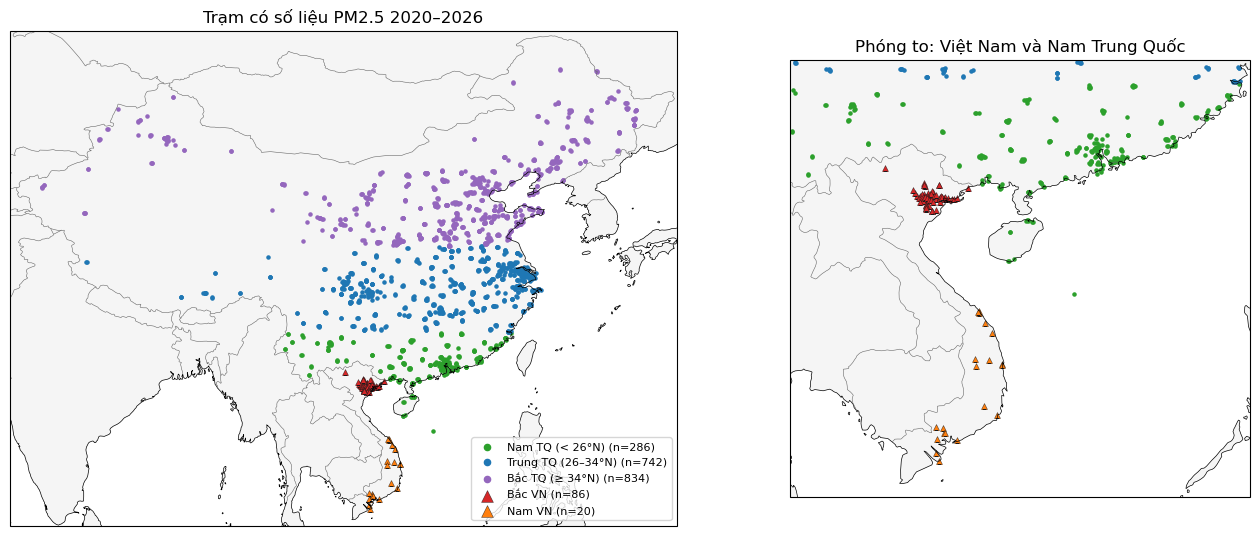

In [4]:
cn_has = cn_st[cn_st['station_code'].isin(cn['station'].unique()) & cn_st['lat'].notna()]

def base_map(ax, extent):
    ax.set_extent(extent, crs=PC)
    ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='0.96')
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'), lw=0.5)
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), lw=0.4, edgecolor='0.4')

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), subplot_kw={'projection': PC},
                         gridspec_kw={'width_ratios': [1.45, 1]})
for ax, extent in zip(axes, [[73, 135, 8, 54], [100, 120, 8, 27]]):
    base_map(ax, extent)
    for z in CNEMC_ZONE_ORDER:
        s = cn_has[cn_has['zone'] == z]
        ax.scatter(s['lon'], s['lat'], s=5, color=GROUP_COLORS[z], transform=PC,
                   label=f'{GROUP_NAMES[z]} (n={len(s)})')
    for z in ['VN-N', 'VN-S']:
        s = vn_meta[vn_meta['zone'] == z]
        ax.scatter(s['lon'], s['lat'], s=18, marker='^', color=GROUP_COLORS[z],
                   edgecolor='k', lw=0.3, transform=PC, label=f'{GROUP_NAMES[z]} (n={len(s)})')
axes[0].legend(loc='lower right', fontsize=8, markerscale=2)
axes[0].set_title('Trạm có số liệu PM2.5 2020–2026')
axes[1].set_title('Phóng to: Việt Nam và Nam Trung Quốc')
save_fig('vncn_2a_map_stations'); plt.show()

### 2.b Khoảng cách tới trạm gần nhất

Các mô hình có trọng số không gian–thời gian (GTWNN, GTW-Tree) và ASTMNN lấy thông tin từ trạm lân cận,
nên mật độ trạm quyết định chúng có bao nhiêu "hàng xóm" để học.

,Bắc VN,Nam VN,Nam TQ (< 26°N),Trung TQ (26–34°N),Bắc TQ (≥ 34°N)
Số trạm,86.0,20.0,286.0,742.0,834.0
KC trạm gần nhất — trung vị (km),3.4,35.7,4.0,3.7,3.7
KC trạm gần nhất — p90 (km),15.2,66.2,11.9,12.1,16.4
Trạm khác trong 50 km (trung vị),41.0,1.0,6.0,6.0,7.0
Trạm khác trong 100 km (trung vị),76.0,3.0,12.0,18.0,15.0
% trạm không có lân cận ≤ 50 km,2.3,30.0,0.7,0.7,1.3


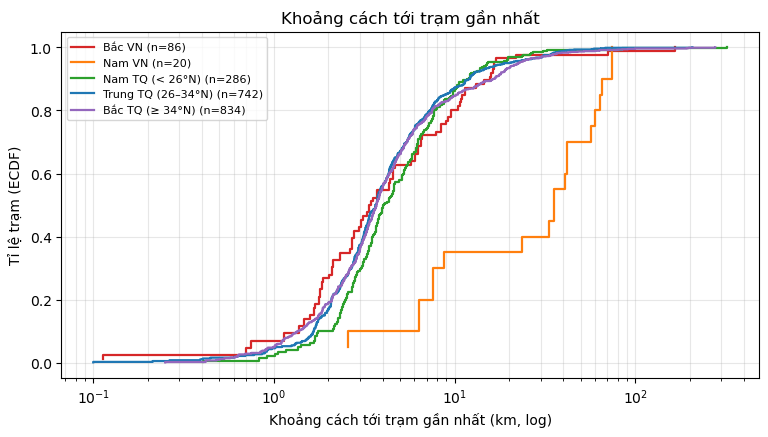

In [5]:
def neighbour_stats(lat, lon):
    la, lo = np.radians(np.asarray(lat)), np.radians(np.asarray(lon))
    a = (np.sin((la[:, None] - la[None]) / 2) ** 2
         + np.cos(la[:, None]) * np.cos(la[None]) * np.sin((lo[:, None] - lo[None]) / 2) ** 2)
    d = 6371 * 2 * np.arcsin(np.sqrt(a))
    np.fill_diagonal(d, np.inf)
    return pd.DataFrame({'nn_km': d.min(1), 'n_50km': (d <= 50).sum(1), 'n_100km': (d <= 100).sum(1)})

nb = {}
for g in GROUPS:
    s = vn_meta[vn_meta['zone'] == g] if g.startswith('VN') else cn_has[cn_has['zone'] == g]
    # neighbours are counted within the whole network, not only inside the zone
    whole = vn_meta if g.startswith('VN') else cn_has
    st = neighbour_stats(whole['lat'], whole['lon'])
    nb[g] = st[(whole['zone'] == g).to_numpy()]

tbl = pd.DataFrame({GROUP_NAMES[g]: {
    'Số trạm': len(v),
    'KC trạm gần nhất — trung vị (km)': v['nn_km'].median(),
    'KC trạm gần nhất — p90 (km)': v['nn_km'].quantile(0.9),
    'Trạm khác trong 50 km (trung vị)': v['n_50km'].median(),
    'Trạm khác trong 100 km (trung vị)': v['n_100km'].median(),
    '% trạm không có lân cận ≤ 50 km': 100 * (v['n_50km'] == 0).mean(),
} for g, v in nb.items()}).round(1)
display(tbl)

fig, ax = plt.subplots(figsize=(9, 4.5))
for g, v in nb.items():
    x = np.sort(v['nn_km'].clip(lower=0.1))
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', color=GROUP_COLORS[g],
            lw=1.6, label=f'{GROUP_NAMES[g]} (n={len(x)})')
ax.set_xscale('log'); ax.set_xlabel('Khoảng cách tới trạm gần nhất (km, log)')
ax.set_ylabel('Tỉ lệ trạm (ECDF)'); ax.set_title('Khoảng cách tới trạm gần nhất')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both')
save_fig('vncn_2b_nn_distance'); plt.show()

### 2.c Số trạm báo cáo theo thời gian (trung bình mỗi giờ trong ngày)

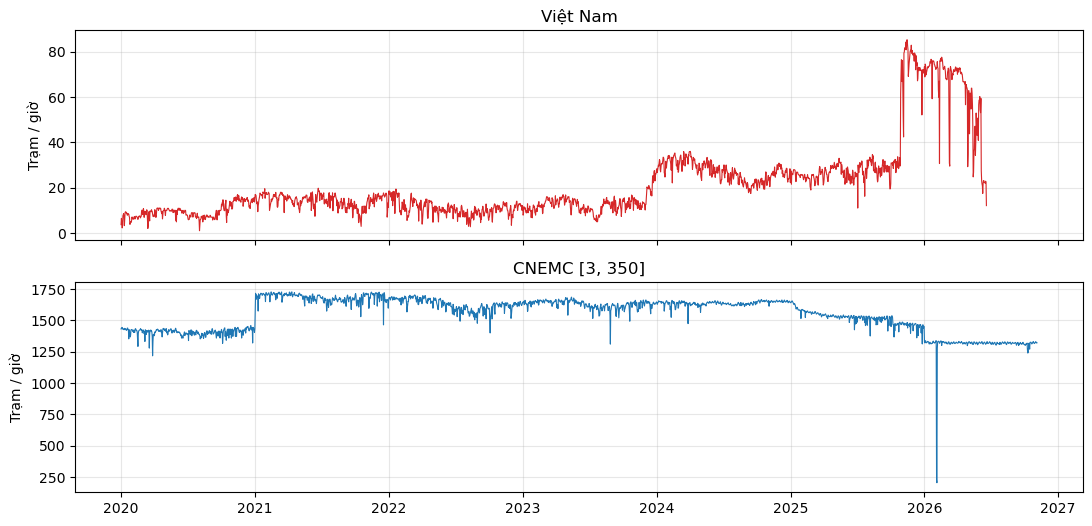

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, (name, df) in zip(axes, [('Việt Nam', vn), ('CNEMC [3, 350]', cn_ok)]):
    n = df.groupby('timestamp').size().resample('D').mean()
    ax.plot(n.index, n.values, lw=0.8, color=NET_COLORS['Việt Nam' if name == 'Việt Nam' else 'CNEMC'])
    ax.set_ylabel('Trạm / giờ'); ax.set_title(name); ax.grid(alpha=0.3)
save_fig('vncn_2c_active_stations'); plt.show()

## 3. Độ phủ thời gian

- **Trong vòng đời trạm**: số giờ có số liệu / số giờ từ bản ghi đầu tới bản ghi cuối của trạm.
- **Theo trạm-năm**: như trên nhưng tính riêng trong từng năm (từ bản ghi đầu tới cuối của trạm trong năm đó),
  để trạm lắp giữa năm không bị tính thiếu phần trước khi lắp.

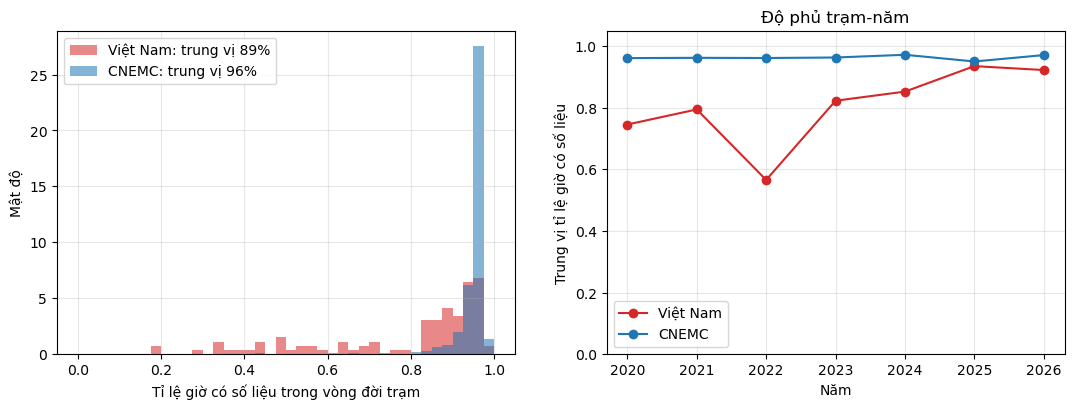

,count,mean,std,min,10%,25%,50%,75%,90%,max
Việt Nam,106.0,0.791,0.209,0.176,0.436,0.678,0.888,0.944,0.958,1.0
CNEMC,1877.0,0.942,0.076,0.015,0.914,0.947,0.960,0.968,0.972,1.0


In [7]:
def life_completeness(df):
    g = df.groupby('station', observed=True)['timestamp']
    span = (g.max() - g.min()) / pd.Timedelta('1h') + 1
    return g.size() / span

def station_year_completeness(df):
    g = df.groupby(['station', 'year'], observed=True)['timestamp']
    span = (g.max() - g.min()) / pd.Timedelta('1h') + 1
    return (g.size() / span).rename('frac').reset_index()

comp = {'Việt Nam': life_completeness(vn), 'CNEMC': life_completeness(cn_ok)}
sy = {'Việt Nam': station_year_completeness(vn), 'CNEMC': station_year_completeness(cn_ok)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(0, 1, 41)
for name, c in comp.items():
    axes[0].hist(c, bins=bins, density=True, alpha=0.55, color=NET_COLORS[name],
                 label=f'{name}: trung vị {c.median():.0%}')
axes[0].set_xlabel('Tỉ lệ giờ có số liệu trong vòng đời trạm'); axes[0].set_ylabel('Mật độ')
axes[0].legend(); axes[0].grid(alpha=0.3)
for name, n in sy.items():
    m = n.groupby('year')['frac'].median()
    axes[1].plot(m.index, m.values, '-o', color=NET_COLORS[name], label=name)
axes[1].set_ylim(0, 1.05); axes[1].set_xlabel('Năm'); axes[1].set_ylabel('Trung vị tỉ lệ giờ có số liệu')
axes[1].set_title('Độ phủ trạm-năm'); axes[1].legend(); axes[1].grid(alpha=0.3)
save_fig('vncn_3_completeness'); plt.show()

pd.DataFrame({k: v.describe(percentiles=[.1, .25, .5, .75, .9]) for k, v in comp.items()}).T.round(3)

## 4. Phân phối giá trị PM2.5 theo giờ

### 4.a Bảng thống kê
`% < 3` và `% > 350` của Việt Nam bằng 0 do QC; cột **CNEMC thô** cho thấy phần CNEMC bị cắt khi giới hạn [3, 350].

In [8]:
def dist_row(v):
    v = np.asarray(v, dtype='float64')
    q = np.quantile(v, [.01, .05, .25, .5, .75, .95, .99])
    return {'n': len(v), 'mean': v.mean(), 'std': v.std(),
            **{f'p{p}': x for p, x in zip([1, 5, 25, 50, 75, 95, 99], q)},
            'max': v.max(), 'CV': v.std() / v.mean(),
            '% < 3': 100 * (v < 3).mean(), '% > 350': 100 * (v > 350).mean(),
            '% > 50': 100 * (v > 50).mean(), '% > 100': 100 * (v > 100).mean()}

rows = {'Việt Nam (QC)': vn[PRIMARY], 'CNEMC thô': cn[PRIMARY], 'CNEMC [3, 350]': cn_ok[PRIMARY]}
rows.update({GROUP_NAMES[g]: of_group(g) for g in GROUPS})
dist = pd.DataFrame({k: dist_row(v) for k, v in rows.items()}).T
dist['n'] = dist['n'].astype(int).map('{:,}'.format)
dist.round(2)

,n,mean,std,p1,p5,p25,p50,p75,p95,p99,max,CV,% < 3,% > 350,% > 50,% > 100
Việt Nam (QC),"1,212,447",26.90,27.80,3.44,4.58,9.87,18.05,32.92,80.87,140.88,350.00,1.03,0.00,0.00,12.96,2.97
CNEMC thô,"92,859,264",31.73,39.04,3.00,4.00,13.00,23.00,40.00,89.00,153.00,200000.00,1.23,0.97,0.05,16.58,3.64
"CNEMC [3, 350]","91,917,332",31.77,30.14,3.00,5.00,13.00,23.00,40.00,89.00,151.00,350.00,0.95,0.00,0.00,16.70,3.63
Bắc VN,"848,866",30.73,30.97,3.53,4.97,10.92,20.71,38.57,92.68,153.48,350.00,1.01,0.00,0.00,16.97,4.11
Nam VN,"363,581",17.93,14.92,3.34,4.06,8.14,14.03,22.92,45.00,71.62,348.66,0.83,0.00,0.00,3.61,0.32
Nam TQ (< 26°N),"14,692,829",22.12,16.79,3.00,4.00,10.00,18.00,29.00,54.00,80.00,350.00,0.76,0.00,0.00,6.19,0.34
Trung TQ (26–34°N),"36,559,141",31.28,26.85,3.00,5.00,14.00,24.00,40.00,83.00,133.00,350.00,0.86,0.00,0.00,16.40,2.80
Bắc TQ (≥ 34°N),"39,950,835",35.78,35.52,3.00,5.00,14.00,25.00,45.00,105.00,178.00,350.00,0.99,0.00,0.00,20.85,5.60


### 4.b Histogram (trục x log) và ECDF theo vùng

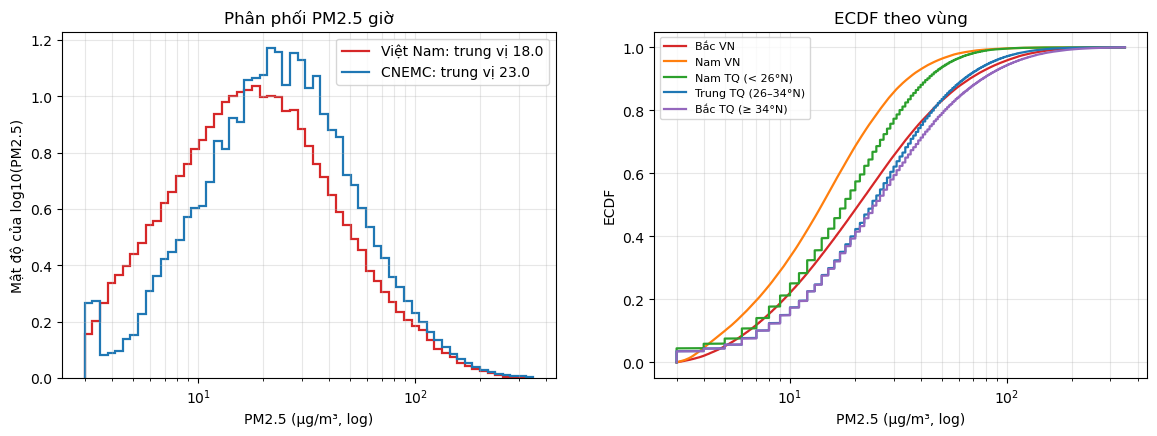

In [9]:
rng = np.random.default_rng(0)
edges = np.linspace(np.log10(3), np.log10(350), 60)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, v in [('Việt Nam', vn[PRIMARY].to_numpy()), ('CNEMC', cn_ok[PRIMARY].to_numpy())]:
    s = rng.choice(v, size=min(len(v), 5_000_000)).astype('float64')
    if name == 'CNEMC':   # integer-valued: spread each value over ±0.5 so log bins are not comb-shaped
        s += rng.uniform(-0.5, 0.5, len(s))
    h, _ = np.histogram(np.log10(s), bins=edges, density=True)
    axes[0].stairs(h, 10 ** edges, color=NET_COLORS[name], lw=1.6,
                   label=f'{name}: trung vị {np.median(v):.1f}')
axes[0].set_xscale('log'); axes[0].set_xlabel('PM2.5 (µg/m³, log)')
axes[0].set_ylabel('Mật độ của log10(PM2.5)'); axes[0].set_title('Phân phối PM2.5 giờ')
axes[0].legend(); axes[0].grid(alpha=0.3, which='both')
for g in GROUPS:
    v = np.sort(of_group(g).to_numpy())
    idx = np.linspace(0, len(v) - 1, 2000).astype(int)   # 2000 điểm là đủ cho đường ECDF
    axes[1].plot(v[idx], (idx + 1) / len(v), color=GROUP_COLORS[g], lw=1.6, label=GROUP_NAMES[g])
axes[1].set_xscale('log'); axes[1].set_xlabel('PM2.5 (µg/m³, log)'); axes[1].set_ylabel('ECDF')
axes[1].set_title('ECDF theo vùng'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which='both')
save_fig('vncn_4b_hist_ecdf'); plt.show()

### 4.c Trung bình ngày và vượt chuẩn 24 giờ

Trung bình ngày theo giờ địa phương, chỉ lấy trạm-ngày có ≥ 18 giờ. Ngưỡng 24 giờ:
WHO 2021 = 15, QCVN 05:2023/BTNMT = 50, GB 3095-2012 loại II (Trung Quốc) = 75 µg/m³.

In [10]:
def daily_means(df):
    d = (df.assign(day=df['timestamp'].dt.normalize())
           .groupby(['station', 'day'], observed=True)
           .agg(pm=(PRIMARY, 'mean'), n=(PRIMARY, 'size'), zone=('zone', 'first')))
    return d[d['n'] >= 18].reset_index()

vn_d, cn_d = daily_means(vn), daily_means(cn_ok)
day_rows = {'Việt Nam': vn_d, 'CNEMC': cn_d}
day_rows.update({GROUP_NAMES[g]: (vn_d if g.startswith('VN') else cn_d).query('zone == @g') for g in GROUPS})
pd.DataFrame({k: {'trạm-ngày': len(d), 'trung vị': d['pm'].median(), 'trung bình': d['pm'].mean(),
                  'p95': d['pm'].quantile(0.95),
                  '% > 15 (WHO)': 100 * (d['pm'] > 15).mean(),
                  '% > 50 (QCVN)': 100 * (d['pm'] > 50).mean(),
                  '% > 75 (GB 3095)': 100 * (d['pm'] > 75).mean()}
              for k, d in day_rows.items()}).T.round(1)

,trạm-ngày,trung vị,trung bình,p95,% > 15 (WHO),% > 50 (QCVN),% > 75 (GB 3095)
Việt Nam,50121.0,19.4,26.9,75.5,63.4,12.3,5.1
CNEMC,3847234.0,24.2,31.8,83.0,74.9,16.1,6.5
Bắc VN,35006.0,22.4,30.7,85.7,67.9,16.8,7.2
Nam VN,15115.0,15.6,18.0,38.7,52.8,2.0,0.2
Nam TQ (< 26°N),612925.0,18.5,22.2,50.0,62.6,5.0,0.8
Trung TQ (26–34°N),1530368.0,24.8,31.4,78.2,76.1,15.6,5.7
Bắc TQ (≥ 34°N),1674067.0,26.3,35.8,96.8,78.4,20.5,9.4


## 5. Phân phối theo trạm

Mỗi trạm một giá trị (trung bình / p95 của mọi giờ trong [3, 350]). Cho thấy khác biệt **giữa các trạm**,
tách khỏi khác biệt **trong một trạm** ở mục 4.

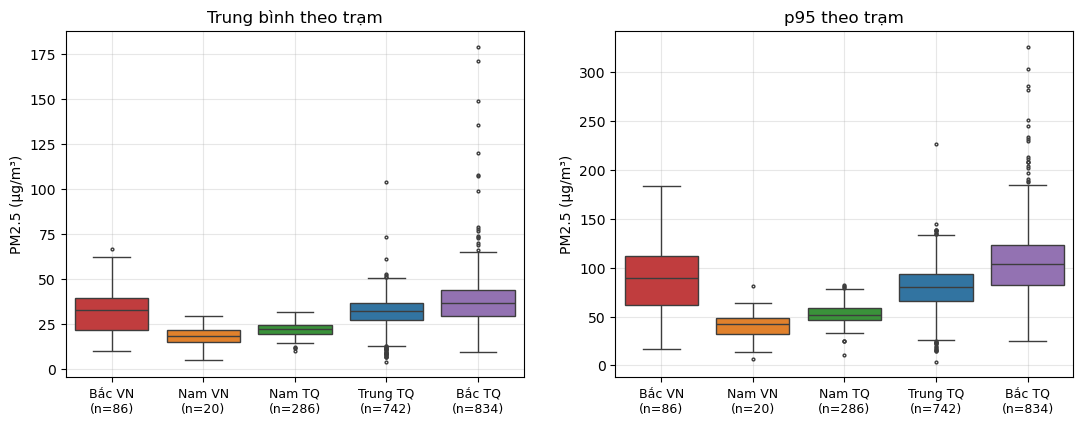

mean                                               p95               \
       count  mean   std   min   25%   50%   75%    max  count   mean   std   
group                                                                         
VN-N    86.0  32.0  13.2   9.7  21.7  32.8  39.1   66.4   86.0   86.8  36.7   
VN-S    20.0  17.8   5.8   4.6  14.7  18.2  21.5   29.3   20.0   41.8  16.4   
CN-S   286.0  22.1   3.9  10.0  19.5  21.8  24.5   31.8  286.0   52.6  10.8   
CN-C   742.0  31.4   8.7   4.0  26.9  32.0  36.4  103.9  742.0   79.6  23.4   
CN-N   834.0  37.4  14.1   9.3  29.2  36.4  43.9  179.3  834.0  104.1  34.2   

                                        
        min   25%    50%    75%    max  
group                                   
VN-N   17.1  62.1   89.6  111.8  183.9  
VN-S    6.9  32.4   42.8   49.0   80.8  
CN-S   10.9  46.0   52.0   59.0   82.0  
CN-C    4.0  66.0   80.5   93.0  226.7  
CN-N   25.0  82.0  103.9  123.0  326.1

In [11]:
def station_stats(df):
    g = df.groupby('station', observed=True)[PRIMARY]
    return pd.DataFrame({'n': g.size(), 'mean': g.mean(), 'p95': g.quantile(0.95)})

vn_ss = station_stats(vn).join(vn_meta.set_index('station')[['zone', 'lat', 'lon']])
cn_ss = (station_stats(cn_ok)
         .join(cn_st.set_index('station_code')[['zone', 'lat', 'lon']]).dropna(subset=['zone']))
ss = pd.concat([vn_ss, cn_ss])
ss['group'] = pd.Categorical(ss['zone'], categories=GROUPS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title in zip(axes, ['mean', 'p95'], ['Trung bình theo trạm', 'p95 theo trạm']):
    sns.boxplot(data=ss, x='group', y=col, order=GROUPS, hue='group', hue_order=GROUPS,
                palette=GROUP_COLORS, legend=False, ax=ax, showfliers=True, fliersize=2)
    ax.set_xticks(range(len(GROUPS)), [f'{GROUP_SHORT[g]}\n(n={(ss.group == g).sum()})' for g in GROUPS], fontsize=9)
    ax.set_xlabel(''); ax.set_ylabel('PM2.5 (µg/m³)'); ax.set_title(title); ax.grid(alpha=0.3)
save_fig('vncn_5a_station_box'); plt.show()

ss.groupby('group', observed=True)[['mean', 'p95']].describe().round(1)

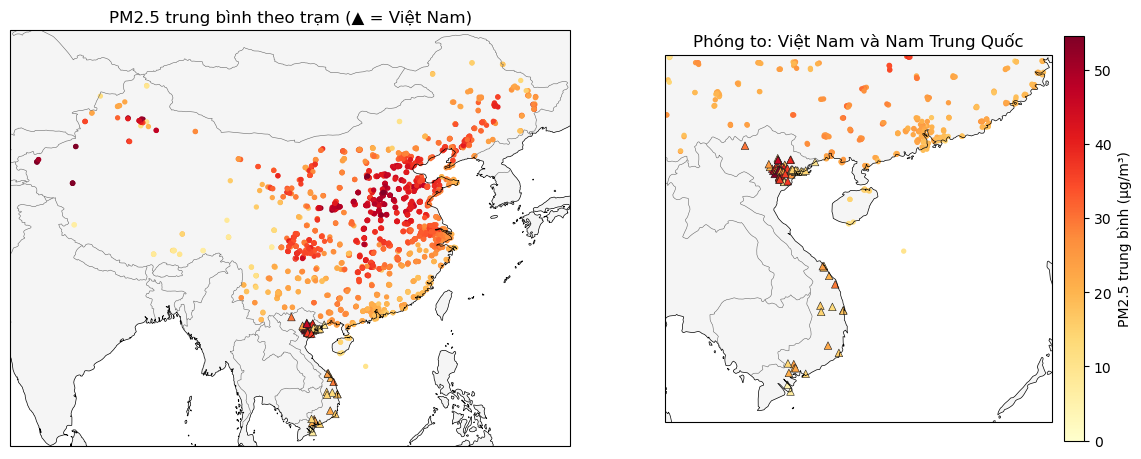

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), subplot_kw={'projection': PC},
                         gridspec_kw={'width_ratios': [1.45, 1]})
vmax = np.nanpercentile(ss['mean'], 98)
for ax, extent in zip(axes, [[73, 135, 8, 54], [100, 120, 8, 27]]):
    base_map(ax, extent)
    sc = ax.scatter(cn_ss['lon'], cn_ss['lat'], c=cn_ss['mean'], s=8, cmap='YlOrRd',
                    vmin=0, vmax=vmax, transform=PC)
    ax.scatter(vn_ss['lon'], vn_ss['lat'], c=vn_ss['mean'], s=30, marker='^', cmap='YlOrRd',
               vmin=0, vmax=vmax, edgecolor='k', lw=0.4, transform=PC)
fig.colorbar(sc, ax=axes, shrink=0.7, pad=0.01, label='PM2.5 trung bình (µg/m³)')
axes[0].set_title('PM2.5 trung bình theo trạm (▲ = Việt Nam)')
axes[1].set_title('Phóng to: Việt Nam và Nam Trung Quốc')
save_fig('vncn_5b_map_station_mean'); plt.show()

## 6. Biến thiên theo thời gian

Trung bình mọi giờ-trạm của vùng. Lưu ý thành phần trạm Việt Nam đổi theo năm (nhiều trạm mới từ 2024),
nên đường Việt Nam phản ánh cả thay đổi mạng trạm.

### 6.a Khí hậu theo tháng và chu kỳ ngày
Chu kỳ ngày theo **giờ địa phương** của mỗi nước (UTC+7 / UTC+8). Panel phải chia cho trung bình vùng để so hình dạng.

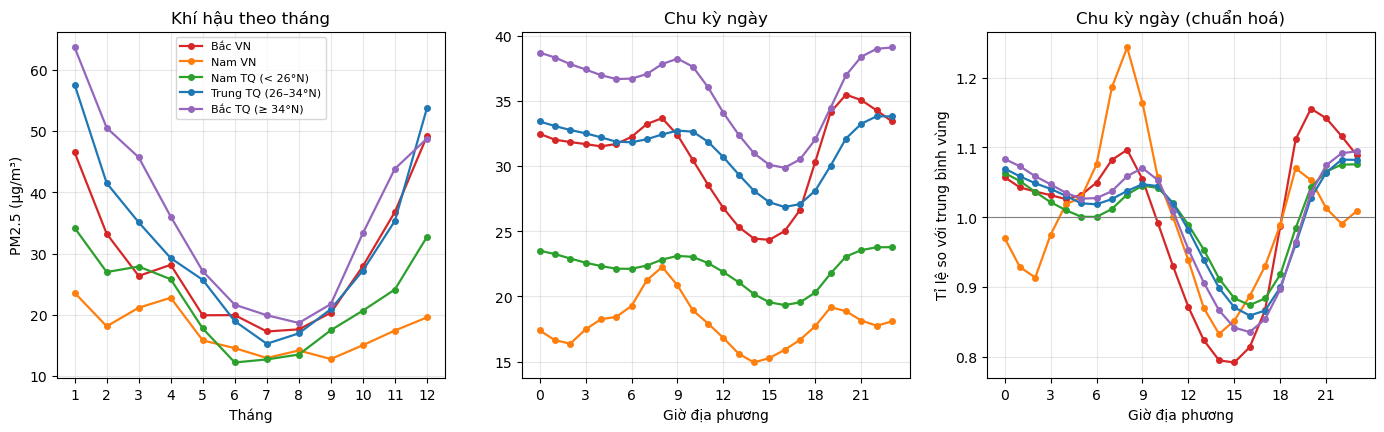

,tháng cao nhất,tháng thấp nhất,cao / thấp (tháng),giờ cao nhất,giờ thấp nhất,cao / thấp (giờ)
Bắc VN,12.0,7.0,2.84,20.0,15.0,1.46
Nam VN,1.0,9.0,1.84,8.0,14.0,1.49
Nam TQ (< 26°N),1.0,6.0,2.79,23.0,16.0,1.23
Trung TQ (26–34°N),1.0,7.0,3.76,22.0,16.0,1.26
Bắc TQ (≥ 34°N),1.0,8.0,3.40,23.0,16.0,1.31


In [13]:
frames = [vn[['zone', 'month', 'hour', 'year', PRIMARY]],
          cn_ok[['zone', 'month', 'hour', 'year', PRIMARY]]]
monthly = pd.concat([f.groupby(['zone', 'month'], observed=True)[PRIMARY].mean() for f in frames])
diurnal = pd.concat([f.groupby(['zone', 'hour'], observed=True)[PRIMARY].mean() for f in frames])
annual = pd.concat([f.groupby(['zone', 'year'], observed=True)[PRIMARY].mean() for f in frames])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for g in GROUPS:
    kw = dict(color=GROUP_COLORS[g], lw=1.6, ms=4, label=GROUP_NAMES[g])
    m = monthly.loc[g]; axes[0].plot(m.index, m.values, '-o', **kw)
    d = diurnal.loc[g]; axes[1].plot(d.index, d.values, '-o', **kw)
    axes[2].plot(d.index, d.values / d.mean(), '-o', **kw)
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel('Tháng'); axes[0].set_ylabel('PM2.5 (µg/m³)')
axes[0].set_title('Khí hậu theo tháng')
axes[1].set_xticks(range(0, 24, 3)); axes[1].set_xlabel('Giờ địa phương'); axes[1].set_title('Chu kỳ ngày')
axes[2].set_xticks(range(0, 24, 3)); axes[2].set_xlabel('Giờ địa phương')
axes[2].set_ylabel('Tỉ lệ so với trung bình vùng'); axes[2].set_title('Chu kỳ ngày (chuẩn hoá)')
axes[2].axhline(1, color='0.5', lw=0.8)
for ax in axes: ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
save_fig('vncn_6a_month_diurnal'); plt.show()

amp = pd.DataFrame({GROUP_NAMES[g]: {
    'tháng cao nhất': int(monthly.loc[g].idxmax()), 'tháng thấp nhất': int(monthly.loc[g].idxmin()),
    'cao / thấp (tháng)': monthly.loc[g].max() / monthly.loc[g].min(),
    'giờ cao nhất': int(diurnal.loc[g].idxmax()), 'giờ thấp nhất': int(diurnal.loc[g].idxmin()),
    'cao / thấp (giờ)': diurnal.loc[g].max() / diurnal.loc[g].min()} for g in GROUPS}).T
amp.round(2)

### 6.b Trung bình năm

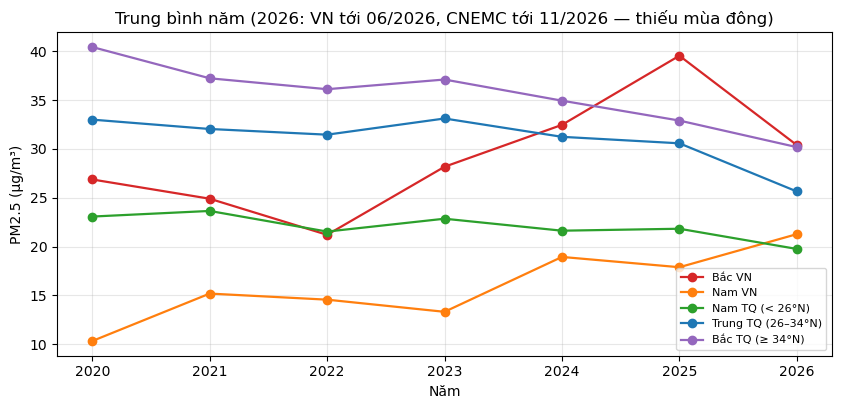

year,2020,2021,2022,2023,2024,2025,2026
zone,,,,,,,
Bắc VN,26.9,24.9,21.2,28.2,32.5,39.5,30.4
Nam VN,10.3,15.2,14.6,13.3,18.9,17.9,21.3
Nam TQ (< 26°N),23.1,23.6,21.5,22.9,21.6,21.8,19.8
Trung TQ (26–34°N),33.0,32.0,31.5,33.1,31.2,30.6,25.6
Bắc TQ (≥ 34°N),40.4,37.2,36.1,37.1,34.9,32.9,30.2


In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for g in GROUPS:
    a = annual.loc[g]
    ax.plot(a.index, a.values, '-o', color=GROUP_COLORS[g], lw=1.6, label=GROUP_NAMES[g])
ax.set_xlabel('Năm'); ax.set_ylabel('PM2.5 (µg/m³)')
ax.set_title('Trung bình năm (2026: VN tới 06/2026, CNEMC tới 11/2026 — thiếu mùa đông)')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
save_fig('vncn_6b_annual'); plt.show()
annual.unstack('year').reindex(GROUPS).rename(index=GROUP_NAMES).round(1)

## 7. Tóm tắt

Số liệu: Việt Nam 2020-01 → 2026-06 (sau QC), CNEMC 2020-01 → 2026-11 (giới hạn [3, 350] trừ khi ghi "thô").

**Cấu trúc dữ liệu**
- **Quy mô.** CNEMC: 1.877 trạm có số liệu, trung vị ~1.600 trạm mỗi giờ, 92,9 triệu giờ-trạm.
  Việt Nam: 106 trạm, trung vị **15 trạm mỗi giờ** (tối đa 88), 1,2 triệu giờ-trạm — ít hơn ~75 lần.
- **Số trạm theo thời gian (2.c).** Việt Nam tăng theo đợt: ~10–15 trạm/giờ tới 2023, ~30 từ 01/2024, ~75 từ 10/2025.
  CNEMC ~1.400 (2020) → ~1.700 (2021) rồi giảm từ 2025, còn ~1.320 trong 2026: 251 trạm có số liệu năm 2023
  không còn số liệu năm 2026, rải khắp Trung Quốc — chưa rõ do CNEMC hay do bản lưu quotsoft.
- **Độ phủ (3).** CNEMC trung vị 96% số giờ trong vòng đời trạm, ~96% mọi năm. Việt Nam 89%, 10% trạm dưới 44%;
  độ phủ trạm-năm thấp nhất năm 2022 (56%), từ 2025 lên ~93%.
- **Độ chính xác giá trị.** CNEMC là số nguyên (bước 1 µg/m³); Việt Nam có 4 chữ số lẻ.
- **CNEMC thô có giá trị lỗi.** Lớn nhất 200.000 µg/m³; 0,97% giờ < 3 và 0,05% > 350. Cần QC trước khi dùng
  (tối thiểu giới hạn [3, 350] như Việt Nam).
- **Mật độ không gian (2.b).** Bắc Việt Nam dày nhưng dồn vào Hà Nội: trung vị 3,4 km tới trạm gần nhất, 41 trạm
  khác trong 50 km. Nam Việt Nam thưa: 35,7 km, 30% trạm không có trạm nào trong 50 km. CNEMC đều hơn:
  3,7–4,0 km, 6–7 trạm trong 50 km, ≤ 1,3% trạm cô lập.

**Phân phối PM2.5**
- **Giờ (4.a).** Trung vị Việt Nam 18,0 so với CNEMC 23,0 µg/m³; trung bình 26,9 so với 31,8. Phần thấp của Việt Nam
  dày hơn, nhưng đuôi trên gần bằng (p99 141 so với 151).
- **Theo vùng.** Bắc VN (TB 30,7; trung vị 20,7; p95 93) gần **Trung TQ** (31,3; 24; 83) hơn Nam TQ (22,1; 18; 54).
  Nam VN thấp nhất (17,9; 14; 45), gần Nam TQ.
- **Khác biệt giữa trạm (5).** Trung bình trạm ở Bắc VN trải từ 10 đến 66 µg/m³ (IQR 22–39), rộng hơn hẳn Nam TQ
  (IQR 20–25) — trạm Việt Nam khác nhau nhiều hơn dù gần nhau hơn. Trạm Trung Quốc có trung bình cao nhất nằm ở
  Tân Cương (Hòa Điền, Kashgar, Aksu — vùng bụi sa mạc).
- **Trung bình ngày (4.c).** Tỉ lệ trạm-ngày vượt QCVN 50 µg/m³: Bắc VN 16,8%, Nam VN 2,0%, Nam TQ 5,0%,
  Trung TQ 15,6%, Bắc TQ 20,5%. Vượt WHO 15 µg/m³: Việt Nam 63%, CNEMC 75%.

**Biến thiên theo thời gian (6)**
- **Mùa.** Mọi vùng cao nhất tháng 12–1, thấp nhất tháng 6–8. Tỉ lệ tháng cao/thấp: Bắc VN 2,8 ≈ Nam TQ 2,8;
  Nam VN yếu nhất (1,8); Trung/Bắc TQ 3,4–3,8. Bắc VN và Nam TQ cùng có đỉnh phụ tháng 3–4.
- **Ngày.** Trung Quốc: đỉnh 22–23 h, đáy 16 h, tỉ lệ cao/thấp 1,23–1,31. Việt Nam dao động mạnh hơn (1,46–1,49)
  và có **đỉnh sáng 7–8 h** (là đỉnh chính ở Nam VN) mà Trung Quốc gần như không có — nhiều khả năng do nguồn
  giao thông giờ cao điểm gần trạm.
- **Năm.** Trung Quốc giảm đều (Bắc TQ 40,4 → 32,9 từ 2020 đến 2025). Việt Nam tăng (Bắc VN 21,2 năm 2022 →
  39,5 năm 2025), nhưng thành phần trạm đổi mạnh trong cùng thời gian nên chưa kết luận được là xu hướng thật.

**Hệ quả khi dùng phương pháp của các paper CNEMC cho Việt Nam**
- Các mô hình dựa vào trạm lân cận (GTWNN, GTW-Tree, ASTMNN) được phát triển trên mạng có 6–18 trạm trong
  50–100 km ở hầu hết mọi nơi. Bắc VN đủ lân cận (nhưng chủ yếu quanh Hà Nội), Nam VN và miền Trung thì không —
  nên dự kiến sai số lớn hơn ở các vùng này.
- Trung vị 15 trạm mỗi giờ nghĩa là mỗi lát thời gian có rất ít mẫu; mô hình học theo từng giờ (như ASTMNN) bị
  ảnh hưởng nhiều hơn mô hình gộp mọi giờ.
- Nếu dùng CNEMC để tiền huấn luyện hoặc so sánh, phân phối Bắc VN gần Trung TQ, còn Nam VN gần Nam TQ.